# Boréal Marché — Final Project: Association Rules & Apriori
**Course:** 420-975-VA — Unsupervised Learning  
**Student:** Abdelhafid Masmi  
**Project:** Building a recommendation engine from 1,000,000 shopping baskets  
**Term:** Fall 2026

This notebook follows **all six phases** of the professor's project brief. It uses the actual dataset files, collects measured evidence, mines with **`mlxtend.frequent_patterns.apriori` only**, and exports JSON files for a separate Streamlit application.

> **Execution note:** Run cells in order from JupyterLab on Fedora. This notebook is deliberately delivered **unexecuted**: all measurements, rule rankings, and conclusions must be produced from real runs. Save the notebook with outputs visible before submission. The separate Streamlit app and README are separate deliverables.

## Setup — reproducibility and resource safety
The notebook lives in `notebooks/`; input data lives in `../data/`. The supplied ZIP contains `transactions.csv`, readable directly with pandas. `products.csv` actually has columns `Item`, `Item_EN`, `Category`, `Price` (the brief mentions `Item_FR`; the real file is authoritative).

Apriori on a million baskets can consume substantial RAM. We use `low_memory=True`, measure process memory, and free intermediate objects. **Never deliberately provoke an out-of-memory crash.**

In [1]:
from pathlib import Path
import gc, json, os, time, threading, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'; MODELS = ROOT / 'models'; REPORTS = ROOT / 'reports'
MODELS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
assert (DATA/'products.csv').exists(), f'Missing {DATA/"products.csv"}'
assert (DATA/'transactions.zip').exists(), f'Missing {DATA/"transactions.zip"}'
print('Project:', ROOT)
print('Python:', platform.python_version(), '| RAM GB:', round(psutil.virtual_memory().total/1e9, 2))
print('Pandas:', pd.__version__)

Project: /home/lab/Documents/boreal-reco-masmi
Python: 3.12.15 | RAM GB: 42.0
Pandas: 3.1.0


## Phase 1 — Load and prepare (10 points)
**Goal:** verify dataset sizes, build the boolean baskets × products matrix, measure elapsed time and memory, identify frequent and rare items, predict a problematic item **before mining**, and examine apparent duplicate products.

In [2]:
t0 = time.perf_counter()
products = pd.read_csv(DATA/'products.csv')
tx = pd.read_csv(DATA/'transactions.zip', usecols=['TransactionID','Date','CustomerID','Item'],
                 dtype={'Item':'category'})
t_load = time.perf_counter()-t0
print('Load seconds:', round(t_load,2))
print('Transaction rows:', len(tx), '| baskets:', tx.TransactionID.nunique())
print('Distinct transaction items:', tx.Item.nunique(), '| catalogue:', len(products))
print('Columns:', products.columns.tolist())
display(products.head(), tx.head())
assert {'Item','Item_EN','Category','Price'}.issubset(products.columns)
assert {'TransactionID','Date','CustomerID','Item'}.issubset(tx.columns)

Load seconds: 2.2
Transaction rows: 8379837 | baskets: 1000000
Distinct transaction items: 98 | catalogue: 98
Columns: ['Item', 'Item_EN', 'Category', 'Price']


,Item,Item_EN,Category,Price
0,Steak de boeuf,Beef steak,Viandes,18.99
1,Saucisses,Sausages,Viandes,7.49
2,Poitrine de poulet,Chicken breast,Viandes,12.99
3,Bacon,Bacon,Viandes,6.99
4,Saumon frais,Fresh salmon,Poissons,16.49


,TransactionID,Date,CustomerID,Item
0,100000,2026-06-19,16595,Cidre de glace
1,100000,2026-06-19,16595,Couches
2,100000,2026-06-19,16595,Fromage cheddar
3,100000,2026-06-19,16595,Lingettes pour bébé
4,100000,2026-06-19,16595,Purée pour bébé


In [3]:
print('Missing values per field:'); display(tx.isna().sum().to_frame('missing'))
print('Repeated basket/item pairs:', tx.duplicated(['TransactionID','Item']).sum())
print('Items not in catalogue:', sorted(set(tx.Item.astype(str))-set(products.Item))[:20])
print('Duplicate catalogue Item keys:', products.Item.duplicated().sum())
print('Duplicate translated labels:', products.Item_EN.duplicated().sum())
print('Unique customers:', tx.CustomerID.nunique())
print('Date range:', tx.Date.min(), 'to', tx.Date.max())
# The average unique items per basket is the correct basket-size statistic.
unique_pairs = tx[['TransactionID','Item']].drop_duplicates()
basket_sizes = unique_pairs.groupby('TransactionID', observed=True).size()
print('Average distinct items per basket:', round(basket_sizes.mean(),3))
print('Median basket size:', basket_sizes.median())

Missing values per field:


,missing
TransactionID,0
Date,0
CustomerID,0
Item,0


Repeated basket/item pairs: 0
Items not in catalogue: []
Duplicate catalogue Item keys: 0
Duplicate translated labels: 0
Unique customers: 32000
Date range: 2026-01-01 to 2026-12-31
Average distinct items per basket: 8.38
Median basket size: 8.0


### Phase 1A — Product frequency and prediction
Frequency here means **fraction of distinct baskets containing a product**, not fraction of transaction rows. The prediction must be recorded before any Apriori run. A very popular item may inflate confidence without strong lift; a very rare item may disappear under support thresholds.

Top 10 most frequent:


,basket_count,support
Item,,
Sac réutilisable,900026,0.900026
Biscuits,161439,0.161439
Noix mélangées,155189,0.155189
Beurre d'arachide,153726,0.153726
Bière,150468,0.150468
Savon à vaisselle,149820,0.149820
Fromage cheddar,143457,0.143457
Charbon de bois,140561,0.140561
Papier hygiénique,139758,0.139758


Five rarest:


,basket_count,support
Item,,
Foie gras,756,0.000756
Vinaigre balsamique vieilli,779,0.000779
Caviar,810,0.000810
Huile de truffe,817,0.000817
Safran,818,0.000818


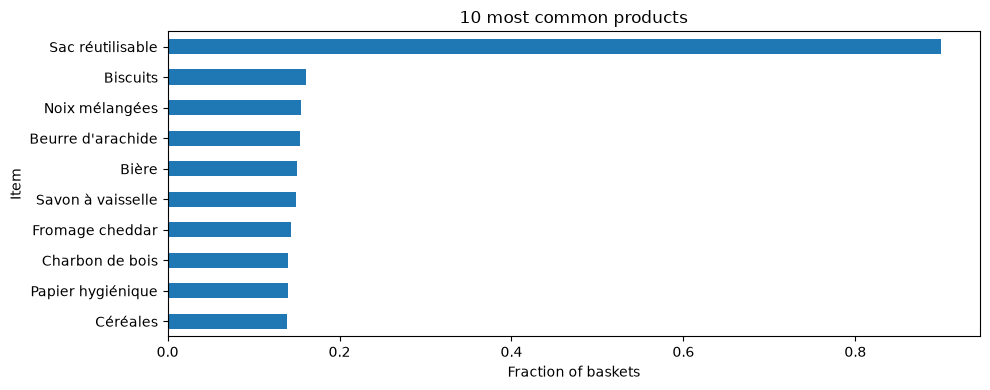

In [4]:
freq_count = unique_pairs.groupby('Item', observed=True).size().sort_values(ascending=False)
frequency = pd.DataFrame({'basket_count':freq_count})
frequency['support'] = frequency.basket_count / basket_sizes.size
print('Top 10 most frequent:'); display(frequency.head(10))
print('Five rarest:'); display(frequency.tail(5).sort_values('basket_count'))
fig, ax = plt.subplots(figsize=(10,4)); frequency.head(10).sort_values('support').support.plot.barh(ax=ax)
ax.set(xlabel='Fraction of baskets', title='10 most common products'); plt.tight_layout(); plt.show()

**Prediction recorded BEFORE mining (edit this text after inspecting the frequency output, before running Phase 2):**

- **Product likely to cause trouble:** `[fill in the actual product from the table]`
- **Reason:** `[e.g., exceptionally high baseline frequency can create high-confidence but low-lift rules; or extremely low frequency can prevent any rule from meeting minimum support]`
- **Expected consequence:** `[specific prediction about confidence, lift, or missing rules]`

Do not rewrite this prediction after seeing the mined rules; evaluate it honestly in Phase 3.

### Phase 1B — Search for duplicate product identities
The professor states that two catalogue entries represent the same underlying product. This is a **semantic** question, not merely identical CSV rows. Examine names and translations before deciding to merge. A merge changes product support and the final 98-product catalogue, so do **not** merge automatically.

In [5]:
display(products.sort_values(['Category','Item_EN']).to_string(index=False))
print('Exact repeated French names:', products[products.duplicated('Item', keep=False)].to_string(index=False))
print('Exact repeated English names:', products[products.duplicated('Item_EN', keep=False)].to_string(index=False))
# Review the full sorted table for synonyms, near-duplicates, and spelling variants.
# Record any semantic duplicates and the merge/no-merge decision in the Markdown cell below.

"                       Item               Item_EN          Category  Price\n                      Bière                  Beer          Boissons  14.99\n                   Thé vert             Green tea          Boissons   5.99\n                 Café moulu         Ground coffee          Boissons  11.99\n             Cidre de glace             Ice cider          Boissons  24.99\n               Jus d'orange          Orange juice          Boissons   4.99\n                  Vin rouge              Red wine          Boissons  17.99\n            Boisson gazeuse            Soft drink          Boissons   5.49\n             Eau pétillante       Sparkling water          Boissons   3.99\n                  Vin blanc            White wine          Boissons  16.99\n                     Bagels                Bagels       Boulangerie   4.49\n                   Baguette              Baguette       Boulangerie   2.99\n           Pain à hamburger           Burger buns       Boulangerie   3.99\n           

Exact repeated French names: Empty DataFrame
Columns: [Item, Item_EN, Category, Price]
Index: []
Exact repeated English names: Empty DataFrame
Columns: [Item, Item_EN, Category, Price]
Index: []


**Duplicate identity investigation (complete after reviewing the catalogue):**

- **Candidate product A:** `[actual catalogue item]`
- **Candidate product B:** `[actual catalogue item]`
- **Evidence they represent the same product:** `[actual evidence]`
- **Decision (merge or retain):** `[decision]`
- **Justification and effect on rule interpretation:** `[reason]`

The code below keeps the original 98 labels unless you explicitly specify a verified mapping. Do not invent a duplicate pair.

In [6]:
# OPTIONAL: after the catalogue review, enter confirmed merges as {old_label: canonical_label}.
# Leave empty to retain original products and 98-column comparability.
MERGE_MAP = {}
if MERGE_MAP:
    unique_pairs = unique_pairs.copy()
    unique_pairs['Item'] = unique_pairs['Item'].astype(str).replace(MERGE_MAP)
    unique_pairs = unique_pairs.drop_duplicates(['TransactionID','Item'])
print('Confirmed merge mapping:', MERGE_MAP)

Confirmed merge mapping: {}


### Phase 1C — Construct the boolean wide table
`pd.crosstab` may temporarily allocate large intermediate objects. Instead, use categorical codes and a compact **NumPy boolean** array (approximately 98 MB for 1,000,000 × 98 values), then wrap it as a pandas DataFrame. Time and resident-memory deltas are measured. The matrix is `True` if a basket contains a product, otherwise `False`.

In [7]:
gc.collect()
proc = psutil.Process(os.getpid())
mem_before = proc.memory_info().rss
start = time.perf_counter()
ids, row_codes = np.unique(unique_pairs['TransactionID'].to_numpy(), return_inverse=True)
items = sorted(unique_pairs['Item'].astype(str).unique())
col_codes = pd.Categorical(unique_pairs['Item'].astype(str), categories=items).codes
matrix = np.zeros((len(ids), len(items)), dtype=np.bool_)
matrix[row_codes, col_codes] = True
basket = pd.DataFrame(matrix, index=pd.Index(ids, name='TransactionID'), columns=items)
wide_seconds = time.perf_counter()-start
mem_after = proc.memory_info().rss
print('Basket shape:', basket.shape, '| boolean:', all(dtype == bool for dtype in basket.dtypes))
print('Wide build time (s):', round(wide_seconds,2))
print('DataFrame deep memory (MiB):', round(basket.memory_usage(deep=True).sum()/2**20,2))
print('Process RSS increase (MiB; approximate):', round((mem_after-mem_before)/2**20,2))
assert int(basket.values.sum()) == len(unique_pairs)
del matrix, row_codes, col_codes, ids
gc.collect()

Basket shape: (1000000, 98) | boolean: True
Wide build time (s): 6.29
DataFrame deep memory (MiB): 101.09
Process RSS increase (MiB; approximate): 566.6


0

## Phase 2 — Apriori at four thresholds (20 points)
Required `min_support` values: **0.05, 0.02, 0.01, 0.005**. For each run measure frequent itemsets, rules, elapsed time, and peak process RSS. `low_memory=True` reduces candidate-generation memory requirements at a possible speed cost. This is **not** a guarantee against OOM; monitor RAM and stop if needed.

**Professor's intended failure:** default Apriori may attempt large intermediate candidate arrays and raise `MemoryError`/be killed. We document the mechanism and use `low_memory=True`; we do not intentionally crash the kernel. A failed run is recorded as a failure rather than fabricated metrics.

In [8]:
class PeakRSS:
    """Sample current process RSS in a background thread during a single benchmark."""
    def __init__(self, interval=0.03):
        self.interval=interval; self.proc=psutil.Process(os.getpid())
        self.stop=threading.Event(); self.peak=0; self.thread=None
    def __enter__(self):
        self.peak=self.proc.memory_info().rss
        def sample():
            while not self.stop.wait(self.interval):
                try: self.peak=max(self.peak,self.proc.memory_info().rss)
                except psutil.Error: break
        self.thread=threading.Thread(target=sample,daemon=True); self.thread.start(); return self
    def __exit__(self,*args):
        self.peak=max(self.peak,self.proc.memory_info().rss)
        self.stop.set(); self.thread.join()

MIN_SUPPORTS=[0.05,0.02,0.01,0.005]
MIN_CONFIDENCE=0.20  # explicitly chosen; document the effect of this choice
LOW_MEMORY=True
print('Thresholds:', MIN_SUPPORTS, '| confidence:', MIN_CONFIDENCE, '| low_memory:', LOW_MEMORY)

Thresholds: [0.05, 0.02, 0.01, 0.005] | confidence: 0.2 | low_memory: True


In [9]:
# WARNING: This cell can take a long time. Run on Fedora, not on a tiny cloud kernel.
benchmarks=[]; mined_by_support={}
for min_sup in MIN_SUPPORTS:
    print(f'\nMining min_support={min_sup} ...', flush=True)
    gc.collect(); baseline=psutil.Process(os.getpid()).memory_info().rss
    started=time.perf_counter(); itemsets=None; rules=None; status='ok'
    try:
        with PeakRSS() as monitor:
            itemsets=apriori(basket, min_support=min_sup, use_colnames=True,
                            low_memory=LOW_MEMORY)
            if len(itemsets):
                rules=association_rules(itemsets, metric='confidence',
                                        min_threshold=MIN_CONFIDENCE)
            else:
                rules=pd.DataFrame()
        peak=monitor.peak
        mined_by_support[min_sup]={'itemsets':itemsets, 'rules':rules}
        n_itemsets=len(itemsets); n_rules=len(rules)
    except (MemoryError, ValueError) as e:
        peak=psutil.Process(os.getpid()).memory_info().rss
        n_itemsets=n_rules=None; status=f'{type(e).__name__}: {str(e)[:140]}'
    elapsed=time.perf_counter()-started
    benchmarks.append({'min_support':min_sup,'itemsets':n_itemsets,'rules':n_rules,
                       'time_seconds':round(elapsed,2),
                       'peak_rss_mib':round(peak/2**20,2),
                       'rss_increase_mib':round((peak-baseline)/2**20,2),
                       'outcome':status})
    print(benchmarks[-1],flush=True)
benchmark_df=pd.DataFrame(benchmarks)
display(benchmark_df)
assert len(benchmark_df)==4


Mining min_support=0.05 ...
{'min_support': 0.05, 'itemsets': 191, 'rules': 282, 'time_seconds': 3.15, 'peak_rss_mib': 1154.62, 'rss_increase_mib': 112.95, 'outcome': 'ok'}

Mining min_support=0.02 ...
{'min_support': 0.02, 'itemsets': 658, 'rules': 3159, 'time_seconds': 6.83, 'peak_rss_mib': 1157.68, 'rss_increase_mib': 87.17, 'outcome': 'ok'}

Mining min_support=0.01 ...
{'min_support': 0.01, 'itemsets': 2267, 'rules': 9736, 'time_seconds': 16.49, 'peak_rss_mib': 1160.95, 'rss_increase_mib': 86.12, 'outcome': 'ok'}

Mining min_support=0.005 ...
{'min_support': 0.005, 'itemsets': 7106, 'rules': 28433, 'time_seconds': 35.66, 'peak_rss_mib': 1167.42, 'rss_increase_mib': 84.12, 'outcome': 'ok'}


,min_support,itemsets,rules,time_seconds,peak_rss_mib,rss_increase_mib,outcome
0,0.050,191,282,3.15,1154.62,112.95,ok
1,0.020,658,3159,6.83,1157.68,87.17,ok
2,0.010,2267,9736,16.49,1160.95,86.12,ok
3,0.005,7106,28433,35.66,1167.42,84.12,ok


### Interpret the benchmark (write from actual measurements)
- **Which threshold was slowest?** `[fill from benchmark]`
- **How did frequent itemsets and rule counts change?** `[fill]`
- **Why default Apriori can fail:** It constructs candidate combinations and intermediate arrays whose size grows rapidly with candidate count and basket count; even a compact boolean input does not guarantee small temporary allocations. `low_memory=True` changes candidate enumeration to lower memory usage, often at a speed cost.
- **Evidence from your runs (not assumptions):** `[fill actual times, peak RSS, errors, and tradeoffs]`

Peak RSS is sampled process resident memory, **not** exact allocation peak; sampling can miss very brief spikes. Document this limitation.

## Phase 3 — Evaluate rules (20 points)
**Support:** the share of all shopping baskets that contain the products in a rule together.  
**Confidence:** among baskets containing the antecedent, the share that also contain the consequent.  
**Lift:** how much more (or less) often the consequent occurs with the antecedent than would be expected from its overall popularity.

Compare **simple rules** (one antecedent and one consequent) by confidence versus lift. The brief requires retaining only `lift > 1` for recommendations.

In [10]:
successful=[s for s in MIN_SUPPORTS if s in mined_by_support and len(mined_by_support[s]['rules'])]
assert successful, 'No association rules were mined. Inspect the benchmark and thresholds.'
# Use the lowest successful support for rule analysis and export.
CHOSEN_SUPPORT=min(successful)
all_rules=mined_by_support[CHOSEN_SUPPORT]['rules'].copy()
all_rules['antecedents']=all_rules['antecedents'].map(lambda x: tuple(sorted(x)))
all_rules['consequents']=all_rules['consequents'].map(lambda x: tuple(sorted(x)))
simple=all_rules[(all_rules.antecedents.map(len)==1)&(all_rules.consequents.map(len)==1)].copy()
def readable(df):
    out=df.copy()
    for col in ['antecedents','consequents']:
        out[col]=out[col].map(lambda x:', '.join(x))
    return out
cols=['antecedents','consequents','support','confidence','lift']
print('Selected support:',CHOSEN_SUPPORT,'| all rules:',len(all_rules),'| simple:',len(simple))
print('Top 10 by confidence:'); display(readable(simple.nlargest(10,'confidence')[cols]))
print('Top 10 by lift:'); display(readable(simple.nlargest(10,'lift')[cols]))

Selected support: 0.005 | all rules: 28433 | simple: 399
Top 10 by confidence:


,antecedents,consequents,support,confidence,lift
180,Concombre,Sac réutilisable,0.062853,0.902619,1.002881
162,Cidre de glace,Sac réutilisable,0.052520,0.902034,1.002231
369,Sauce tomate,Sac réutilisable,0.095588,0.901808,1.001980
350,Relish,Sac réutilisable,0.053301,0.901695,1.001854
265,Huile d'olive,Sac réutilisable,0.049201,0.901662,1.001818
340,Pommes,Sac réutilisable,0.082351,0.901617,1.001768
304,Moutarde de Dijon,Sac réutilisable,0.074374,0.901525,1.001665
244,Fromage suisse,Sac réutilisable,0.083997,0.901458,1.001592
375,Steak de boeuf,Sac réutilisable,0.095092,0.901414,1.001543
28,Avocat,Sac réutilisable,0.039907,0.901344,1.001464


Top 10 by lift:


,antecedents,consequents,support,confidence,lift
100,Fromage à raclette,Bouillon à fondue,0.033651,0.491198,10.170786
101,Bouillon à fondue,Fromage à raclette,0.033651,0.696780,10.170786
152,Fromage à raclette,Charcuteries,0.031932,0.466106,9.975519
153,Charcuteries,Fromage à raclette,0.031932,0.683403,9.975519
184,Fromage à raclette,Cornichons,0.029733,0.434008,9.772967
185,Cornichons,Fromage à raclette,0.029733,0.669526,9.772967
245,Fromage à raclette,Pain baguette rustique,0.027627,0.403267,9.551784
246,Pain baguette rustique,Fromage à raclette,0.027627,0.654374,9.551784
15,Riz à sushi,Algues nori,0.054431,0.650738,9.504685
16,Algues nori,Riz à sushi,0.054431,0.795019,9.504685


### Phase 3 interpretation (complete using the two actual tables)
- **Top confidence patterns:** `[identify actual products and metrics]`
- **Top lift patterns:** `[identify actual products and metrics]`
- **Why rankings differ:** Confidence depends strongly on how common the consequent already is. Lift adjusts for its baseline frequency. A common item can generate high confidence with modest lift; a less common but unusually associated item can have high lift.
- **Was the Phase 1 prediction correct?** `[quote the earlier prediction and evaluate it with specific observed rules]`
- **Why retain `lift > 1`?** Those rules indicate positive association relative to the consequent's baseline popularity. This is a useful filter, **not** proof of causation or usefulness.

**Important:** This comparison is the professor's most heavily weighted interpretive question; cite actual rule values.

In [11]:
positive_rules=all_rules[all_rules['lift']>1].copy()
positive_rules=positive_rules.sort_values(['lift','confidence'],ascending=False)
print('Positive-lift rules:',len(positive_rules))
display(readable(positive_rules[cols].head(20)))

Positive-lift rules: 26991


,antecedents,consequents,support,confidence,lift
26094,"Bouillon à fondue, Charcuteries, Pain baguette...","Cornichons, Fromage à raclette",0.005029,0.559648,18.822465
26116,"Bouillon à fondue, Charcuteries, Pain baguette...","Cornichons, Fromage à raclette, Sac réutilisable",0.005029,0.501446,18.765982
19820,"Bouillon à fondue, Charcuteries, Pain baguette...","Cornichons, Fromage à raclette",0.005595,0.557882,18.763063
26108,"Cornichons, Fromage à raclette, Pain baguette ...","Bouillon à fondue, Charcuteries, Sac réutilisable",0.005029,0.335557,18.684642
26105,"Bouillon à fondue, Charcuteries, Sac réutilisable","Cornichons, Fromage à raclette, Pain baguette ...",0.005029,0.280027,18.684642
19819,"Bouillon à fondue, Cornichons, Pain baguette r...","Charcuteries, Fromage à raclette",0.005595,0.596164,18.669801
19812,"Cornichons, Fromage à raclette, Pain baguette ...","Bouillon à fondue, Charcuteries",0.005595,0.373324,18.666177
19826,"Bouillon à fondue, Charcuteries","Cornichons, Fromage à raclette, Pain baguette ...",0.005595,0.279750,18.666177
26115,"Bouillon à fondue, Cornichons, Pain baguette r...","Charcuteries, Fromage à raclette, Sac réutilis...",0.005029,0.535855,18.660506
26086,"Cornichons, Fromage à raclette, Pain baguette ...","Bouillon à fondue, Charcuteries",0.005029,0.373016,18.650794


## Phase 4 — Seasonal analysis (10 points)
Mine separately on **June–August** and **December–February**. Compare support, confidence, and lift for the **same rules** in both seasons, and find a rule present in one but absent in the other. The date must be parsed and validated first. Seasonal support denominators are seasonal basket counts, not annual basket counts.

In [12]:
dates=tx[['TransactionID','Date']].drop_duplicates('TransactionID').copy()
dates['Date']=pd.to_datetime(dates['Date'],errors='coerce')
assert dates.Date.notna().all(), 'Unparseable dates; inspect source data'
print('Date range:',dates.Date.min(),dates.Date.max())
print('Unique months:',sorted(dates.Date.dt.month.unique().tolist()))
season_ids={
 'summer':set(dates.loc[dates.Date.dt.month.isin([6,7,8]),'TransactionID']),
 'winter':set(dates.loc[dates.Date.dt.month.isin([12,1,2]),'TransactionID'])
}
for season, ids_for_season in season_ids.items(): print(season,'baskets:',len(ids_for_season))

Date range: 2026-01-01 00:00:00 2026-12-31 00:00:00
Unique months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
summer baskets: 252474
winter baskets: 246965


In [13]:
# Seasonal mining uses the same support/confidence thresholds and low-memory setting.
seasonal={}
for season, chosen_ids in season_ids.items():
    sub=basket.loc[basket.index.isin(chosen_ids)]
    started=time.perf_counter()
    with PeakRSS() as peak:
        fi=apriori(sub,min_support=CHOSEN_SUPPORT,use_colnames=True,low_memory=True)
        rr=association_rules(fi,metric='confidence',min_threshold=MIN_CONFIDENCE) if len(fi) else pd.DataFrame()
    if len(rr):
        rr=rr.copy()
        rr['antecedents']=rr.antecedents.map(lambda x:tuple(sorted(x)))
        rr['consequents']=rr.consequents.map(lambda x:tuple(sorted(x)))
    seasonal[season]={'rules':rr,'baskets':len(sub),'seconds':time.perf_counter()-started,
                      'peak_rss_mib':peak.peak/2**20}
    print(season,'rules:',len(rr),'seconds:',round(seasonal[season]['seconds'],2),
          'peak RSS MiB:',round(seasonal[season]['peak_rss_mib'],2))
    del sub,fi; gc.collect()

summer rules: 64011 seconds: 12.92 peak RSS MiB: 1057.14
winter rules: 18348 seconds: 7.56 peak RSS MiB: 1074.4


In [14]:
def season_table(rr, season):
    if rr.empty: return pd.DataFrame(columns=['antecedents','consequents',f'{season}_support',f'{season}_confidence',f'{season}_lift'])
    return rr[['antecedents','consequents','support','confidence','lift']].rename(
        columns={k:f'{season}_{k}' for k in ['support','confidence','lift']})
comparison=season_table(seasonal['summer']['rules'],'summer').merge(
    season_table(seasonal['winter']['rules'],'winter'),
    on=['antecedents','consequents'],how='outer',indicator=True)
print('Rules in both:',(comparison._merge=='both').sum())
print('Summer only:',(comparison._merge=='left_only').sum())
print('Winter only:',(comparison._merge=='right_only').sum())
print('Shared rules:'); display(readable(comparison[comparison._merge=='both'].head(15)))
print('Rules found in only one season:'); display(readable(comparison[comparison._merge!='both'].head(15)))

Rules in both: 12324
Summer only: 51687
Winter only: 6024
Shared rules:


,antecedents,consequents,summer_support,summer_confidence,summer_lift,winter_support,winter_confidence,winter_lift,_merge
0,Ail,Champignons,0.024101,0.297919,5.491083,0.023424,0.294507,5.498406,both
1,Ail,"Champignons, Pâtes alimentaires",0.023741,0.293464,7.228488,0.023117,0.290638,7.316011,both
2,Ail,"Champignons, Pâtes alimentaires, Sac réutilisable",0.021420,0.264774,7.246443,0.020906,0.262842,7.348054,both
4,Ail,"Champignons, Pâtes alimentaires, Sauce tomate",0.018073,0.223403,7.275977,0.017500,0.220027,7.305605,both
5,Ail,"Champignons, Sac réutilisable",0.021757,0.268935,5.498350,0.021197,0.266507,5.527668,both
7,Ail,"Champignons, Sauce tomate",0.018077,0.223452,7.197720,0.017505,0.220078,7.229537,both
8,Ail,Parmesan râpé,0.043909,0.542766,6.159401,0.042549,0.534949,6.213311,both
9,Ail,"Parmesan râpé, Pâtes alimentaires",0.043612,0.539094,7.244759,0.042229,0.530927,7.335407,both
10,Ail,"Parmesan râpé, Pâtes alimentaires, Sac réutili...",0.039248,0.485141,7.240375,0.037985,0.477575,7.344890,both
11,Ail,"Parmesan râpé, Pâtes alimentaires, Sac réutili...",0.030070,0.371701,7.271418,0.029049,0.365219,7.333633,both


Rules found in only one season:


,antecedents,consequents,summer_support,summer_confidence,summer_lift,winter_support,winter_confidence,winter_lift,_merge
3,Ail,"Champignons, Pâtes alimentaires, Sac réutilisa...",0.016370,0.202350,7.307700,NaN,NaN,NaN,left_only
6,Ail,"Champignons, Sac réutilisable, Sauce tomate",0.016374,0.202399,7.227792,NaN,NaN,NaN,left_only
35,"Ail, Baguette",Sac réutilisable,NaN,NaN,NaN,0.005074,0.909289,1.010264,right_only
72,"Ail, Beurre d'arachide","Parmesan râpé, Pâtes alimentaires, Sauce tomate",0.005121,0.404568,7.132390,NaN,NaN,NaN,left_only
74,"Ail, Beurre d'arachide","Parmesan râpé, Sauce tomate",0.005121,0.404568,7.088830,NaN,NaN,NaN,left_only
79,"Ail, Beurre d'arachide","Pâtes alimentaires, Vin rouge",0.005022,0.396746,7.372886,NaN,NaN,NaN,left_only
83,"Ail, Beurre d'arachide",Vin rouge,0.005098,0.402691,5.966839,NaN,NaN,NaN,left_only
86,"Ail, Beurre d'arachide, Parmesan râpé","Pâtes alimentaires, Sauce tomate",0.005121,0.762832,8.684457,NaN,NaN,NaN,left_only
88,"Ail, Beurre d'arachide, Parmesan râpé",Sauce tomate,0.005121,0.762832,7.514738,NaN,NaN,NaN,left_only
90,"Ail, Beurre d'arachide, Parmesan râpé, Pâtes a...",Sauce tomate,0.005121,0.767815,7.563824,NaN,NaN,NaN,left_only


### Seasonal conclusions (fill from observed rules)
- **Shared rule and both sets of metrics:** `[copy one actual rule and summer/winter support, confidence, lift]`
- **Rule present in one season only:** `[identify from comparison; if none, explicitly say none at chosen thresholds and test a justified alternative threshold]`
- **Important distinction:** A rule absent from mined results does **not** mean the combination never occurred; it may simply fall below the mining thresholds.
- **Recommended re-mining frequency:** `[propose a cadence supported by the observed seasonal differences, e.g. before major seasonal changes, with monitoring]`
- **Risk of using annual rules in January:** `[ground in observed seasonal changes]`

## Phase 5 — Save rules for the online app
The Streamlit app must **never call Apriori**. We export human-readable antecedents/consequents, metrics, and metadata. Include a product-popularity fallback for empty/no-match baskets. A recommendation matches a rule when its antecedent is a **subset** of the current basket. For duplicate suggested products, retain the rule with the **highest lift**.

In [15]:
def export_rule(row):
    return {'antecedents':list(row.antecedents),'consequents':list(row.consequents),
            'support':float(row.support),'confidence':float(row.confidence),'lift':float(row.lift)}
exported=[export_rule(r) for r in positive_rules.itertuples(index=False)]
with open(MODELS/'rules.json','w',encoding='utf-8') as f:
    json.dump(exported,f,ensure_ascii=False,indent=2)
recommendable=set(x for r in exported for x in r['consequents'])
coverage=len(recommendable)/len(products)
metadata={
 'project':'Boreal Marche Apriori', 'min_support':CHOSEN_SUPPORT,
 'min_confidence':MIN_CONFIDENCE,'min_lift_exclusive':1.0,
 'low_memory':LOW_MEMORY,'mining_date_utc':datetime.now(timezone.utc).isoformat(),
 'number_of_rules':len(exported),'recommendable_products':len(recommendable),
 'catalogue_products':len(products),'coverage':coverage,
 'number_of_baskets':int(len(basket)),'benchmark_measurement':'sampled process RSS',
 'merge_map':MERGE_MAP}
with open(MODELS/'metadata.json','w',encoding='utf-8') as f:
    json.dump(metadata,f,ensure_ascii=False,indent=2)
popularity=frequency.reset_index().rename(columns={'Item':'item'})
popularity['item']=popularity['Item'] if 'Item' in popularity.columns else popularity.iloc[:,0]
with open(MODELS/'popularity.json','w',encoding='utf-8') as f:
    json.dump([{'item':str(r.item),'support':float(r.support),'basket_count':int(r.basket_count)}
               for r in popularity.itertuples(index=False)],f,ensure_ascii=False,indent=2)
print('Saved rules:',len(exported),'| coverage:',f'{coverage:.1%}')
print('Files:',*[str(p) for p in MODELS.glob('*.json')],sep='\n - ')

Saved rules: 26991 | coverage: 59.2%
Files:
 - /home/lab/Documents/boreal-reco-masmi/models/rules.json
 - /home/lab/Documents/boreal-reco-masmi/models/metadata.json
 - /home/lab/Documents/boreal-reco-masmi/models/popularity.json


### Offline recommendation logic and edge-case tests
The app is a separate deliverable, but we verify its essential rule-selection logic here. The fallback is most popular **eligible** items. Rule explanations and strength labels will be rendered by the Streamlit app.

In [16]:
def recommend(current_basket, rules=exported, limit=5):
    chosen=set(current_basket); best={}
    for r in rules:
        if set(r['antecedents']).issubset(chosen):
            for candidate in r['consequents']:
                if candidate in chosen: continue
                if candidate not in best or r['lift']>best[candidate]['lift']:
                    best[candidate]=r
    ranked=sorted(best.items(),key=lambda pair:(-pair[1]['lift'],-pair[1]['confidence'],pair[0]))
    if ranked: return [{'item':name,'rule':rule,'fallback':False} for name,rule in ranked[:limit]]
    # Empty basket or no matching rule: popular-products fallback.
    return [{'item':str(name),'rule':None,'fallback':True}
            for name in frequency.index.astype(str) if name not in chosen][:limit]

assert all(x['fallback'] for x in recommend([]))
example_item=str(frequency.index[0]); example=recommend([example_item])
assert all(x['item']!=example_item for x in example)
assert len({x['item'] for x in example})==len(example)
assert len(example)<=5
print('Empty basket fallback:',[x['item'] for x in recommend([])])
print('Example basket:',example_item,'->',[x['item'] for x in example])
print('Basic edge-case checks passed')

Empty basket fallback: ['Sac réutilisable', 'Biscuits', 'Noix mélangées', "Beurre d'arachide", 'Bière']
Example basket: Sac réutilisable -> ['Biscuits', 'Noix mélangées', "Beurre d'arachide", 'Bière', 'Savon à vaisselle']
Basic edge-case checks passed


## Phase 6 — Benchmark, coverage, limitations (10 points)
The professor requests a table in `reports/benchmark.md` with **four thresholds**, itemset count, rule count, elapsed time, peak memory, and outcome. The code below writes your actual measured results, never placeholders disguised as measurements.

In [17]:
def cellfmt(v):
    if pd.isna(v): return 'N/A'
    return str(v).replace('|','/')
headers=['min_support','itemsets','rules','time_seconds','peak_rss_mib','outcome']
lines=['# Boréal Marché — Apriori benchmark','','Measured on '+platform.platform(),
       '',f'- RAM available: {psutil.virtual_memory().total/2**30:.2f} GiB',
       f'- Python: {platform.python_version()}',
       f'- Apriori `low_memory`: {LOW_MEMORY}',
       f'- Rule confidence threshold: {MIN_CONFIDENCE}',
       '- Peak memory is sampled process RSS (MiB), not exact allocation peak.','',
       '| '+ ' | '.join(headers)+' |', '|'+ '|'.join(['---']*len(headers))+'|']
for _, r in benchmark_df.iterrows():
    lines.append('| '+' | '.join(cellfmt(r[k]) for k in headers)+' |')
lines += ['','## Interpretation','',
          'Fill in the observed performance tradeoffs and any errors here after reviewing the notebook.',
          '', '## Apriori memory limitation','',
          'Candidate generation can allocate large intermediate arrays. `low_memory=True` trades speed for lower memory use.',
          '', '## Recommendation coverage','',
          f'{len(recommendable)} of {len(products)} catalogue products = {coverage:.1%}.',
          '', '## Known limitations','',
          '1. **Cold start and sparse rules:** uncommon items may have no qualifying rules; use popularity fallback and consider content-based recommendations.',
          '2. **Seasonal changes:** annual rules can become stale; re-mine periodically and monitor seasonal differences.',
          '3. **Correlation is not causation:** co-purchase association alone does not prove one product causes purchase of another.',
          '']
(REPORTS/'benchmark.md').write_text('\n'.join(lines),encoding='utf-8')
print('Wrote:',REPORTS/'benchmark.md')
display(benchmark_df)
print(f'Coverage: {len(recommendable)}/{len(products)} = {coverage:.1%}')

Wrote: /home/lab/Documents/boreal-reco-masmi/reports/benchmark.md


,min_support,itemsets,rules,time_seconds,peak_rss_mib,rss_increase_mib,outcome
0,0.050,191,282,3.15,1154.62,112.95,ok
1,0.020,658,3159,6.83,1157.68,87.17,ok
2,0.010,2267,9736,16.49,1160.95,86.12,ok
3,0.005,7106,28433,35.66,1167.42,84.12,ok


Coverage: 58/98 = 59.2%


### Ethical and legal discussion (required by the brief)
- **Québec Law 25 / transparency:** show the triggering basket items and support/confidence/lift in an auditable **“Rules that fired”** section. The professor frames explainability as important for automated recommendations; the specific legal applicability depends on context and should not be overstated.
- **Correlation is not causation:** the brief says a rule will resemble a famous retail analytics example. **Identify the actual rule from your mined results** and explain why the data does not establish causality; do not claim it exists before verifying.
- **Reinforcement bias:** a popularity-only recommender can repeatedly promote already popular items, reducing exposure for the rest of the catalogue. Report coverage and consider diversity strategies.

**Evidence to add after execution:** `[actual notable rule, metrics, and explanation]`.

## Final verification and submission checklist
- [ ] Notebook **executed** from top to bottom and all outputs visible; save before submission.
- [ ] Prediction entered **before** Phase 2 and revisited honestly in Phase 3.
- [ ] Semantic duplicate-product investigation completed and justified.
- [ ] All four Apriori benchmarks contain **real** timing and memory measurements.
- [ ] Confidence vs lift comparison includes observed examples.
- [ ] Summer vs winter comparison includes actual shared and seasonal-only rules.
- [ ] `models/rules.json`, `models/metadata.json`, and `reports/benchmark.md` created.
- [ ] Coverage computed and limitations documented.
- [ ] Separate Streamlit app implements catalogue, basket, recommendations, explanations, “Rules that fired”, and all five edge cases.
- [ ] README, screenshots, requirements, and public repository prepared.

**Instructor submission deadline:** Wednesday, November 4, 2026 at 23:59 EST. The final submission is a single Git repository URL. The notebook alone does not satisfy all deliverables.